<a href="https://colab.research.google.com/github/Kartheek-777/TNS-Training/blob/main/Logistic_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Logistic Regression — Heart Disease Prediction

In this module, we will build a Logistic Regression model using a real-world
heart disease dataset from Kaggle.

We will:

1. Download the dataset using the Kaggle API
2. Explore and clean the data
3. Perform Exploratory Data Analysis
4. Prepare features and target
5. Split the data into training and testing sets
6. Train a Logistic Regression model
7. Generate probability predictions
8. Convert probabilities into classes
9. Evaluate the model
10. Visualize the results
11. Test the model on new data

### Prediction Problem

We want to predict whether a patient has a 10-year risk of coronary heart disease.

Target:

TenYearCHD

0 → No 10-year CHD risk

1 → 10-year CHD risk

In [1]:
!pip install kaggle

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import(confusion_matrix,
                            classification_report,
                            accuracy_score,
                            recall_score,
                            f1_score,
                            precision_score,
                            roc_auc_score,
                            roc_curve
                            )
print("Libraries imported Successfully!")

Libraries imported Successfully!


In [3]:
import os
from getpass import getpass

kaggle_token = getpass("Enter your Kaggle API token: ")
os.environ['KAGGLE_API_token'] = kaggle_token
del kaggle_token
print("Kaggle API token imported Successfully!")


Enter your Kaggle API token: ··········
Kaggle API token imported Successfully!


In [4]:
!mkdir -p /content/heart_disease_dataset

!kaggle datasets download \
    -d dileep070/heart-disease-prediction-using-logistic-regression \
    -p /content/heart_disease_dataset \
    --unzip

Dataset URL: https://www.kaggle.com/datasets/dileep070/heart-disease-prediction-using-logistic-regression
License(s): unknown
100% 58.4k/58.4k [00:00<00:00, 46.9MB/s]



In [5]:
os.listdir("/content/heart_disease_dataset")

['framingham.csv']

In [7]:
csv_files = [
    file
    for file in os.listdir("/content/heart_disease_dataset")
    if file.endswith(".csv")
]
csv_files

['framingham.csv']

In [9]:
dataset_path = os.path.join("/content/heart_disease_dataset", csv_files[0])
df = pd.read_csv(dataset_path)
df.head()

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


In [11]:
Rows = df.shape[0]
Columns = df.shape[1]

print("Rows :",Rows)
print("Columns :",Columns)

Rows : 4238
Columns : 16


In [12]:
print("Columns :")

for i in df.columns:
  print(i)

Columns :
male
age
education
currentSmoker
cigsPerDay
BPMeds
prevalentStroke
prevalentHyp
diabetes
totChol
sysBP
diaBP
BMI
heartRate
glucose
TenYearCHD


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4238 entries, 0 to 4237
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   male             4238 non-null   int64  
 1   age              4238 non-null   int64  
 2   education        4133 non-null   float64
 3   currentSmoker    4238 non-null   int64  
 4   cigsPerDay       4209 non-null   float64
 5   BPMeds           4185 non-null   float64
 6   prevalentStroke  4238 non-null   int64  
 7   prevalentHyp     4238 non-null   int64  
 8   diabetes         4238 non-null   int64  
 9   totChol          4188 non-null   float64
 10  sysBP            4238 non-null   float64
 11  diaBP            4238 non-null   float64
 12  BMI              4219 non-null   float64
 13  heartRate        4237 non-null   float64
 14  glucose          3850 non-null   float64
 15  TenYearCHD       4238 non-null   int64  
dtypes: float64(9), int64(7)
memory usage: 529.9 KB


In [15]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
male,4238.0,0.429212,0.495022,0.00,0.00,0.0,1.000,1.0
age,4238.0,49.584946,8.572160,32.00,42.00,49.0,56.000,70.0
education,4133.0,1.978950,1.019791,1.00,1.00,2.0,3.000,4.0
currentSmoker,4238.0,0.494101,0.500024,0.00,0.00,0.0,1.000,1.0
cigsPerDay,4209.0,9.003089,11.920094,0.00,0.00,0.0,20.000,70.0
BPMeds,4185.0,0.029630,0.169584,0.00,0.00,0.0,0.000,1.0
prevalentStroke,4238.0,0.005899,0.076587,0.00,0.00,0.0,0.000,1.0
prevalentHyp,4238.0,0.310524,0.462763,0.00,0.00,0.0,1.000,1.0
diabetes,4238.0,0.025720,0.158316,0.00,0.00,0.0,0.000,1.0
totChol,4188.0,236.721585,44.590334,107.00,206.00,234.0,263.000,696.0


In [17]:
# Check Missing Values

missing_values = df.isnull().sum()
missing_values = (
    missing_values[missing_values > 0]
    .sort_values(ascending=False)
)

missing_values

,0
glucose,388
education,105
BPMeds,53
totChol,50
cigsPerDay,29
BMI,19
heartRate,1


In [18]:
# Missing Value Percentage

missing_values_percentage = (
    df.isnull().mean() * 100
).sort_values(ascending=False)

missing_values_percentage

,0
glucose,9.155262
education,2.477584
BPMeds,1.250590
totChol,1.179802
cigsPerDay,0.684285
BMI,0.448325
heartRate,0.023596
male,0.000000
prevalentHyp,0.000000
prevalentStroke,0.000000


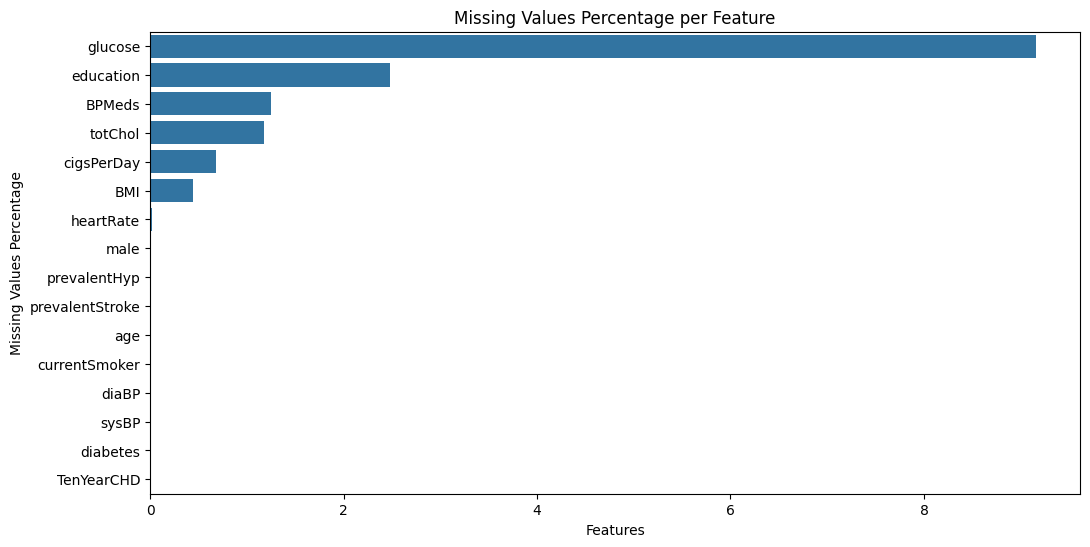

In [22]:
# Visualize Missing Values

plt.figure(figsize=(12, 6))
sns.barplot(
    x=missing_values_percentage.values,
    y=missing_values_percentage.index
)

plt.xlabel("Features")
plt.ylabel("Missing Values Percentage")
plt.title("Missing Values Percentage per Feature")
plt.show()


In [23]:
# Check Duplicate Rows

Duplicated_rows = df.duplicated().sum()
print("Duplicated Rows :", Duplicated_rows)

Duplicated Rows : 0
